# Build Forcing Validation - Temperature
- Tony Grove

In [1]:
path_env = 'desktop'  # Change this to 'desktop' or 'alpine' as needed

In [2]:
import os

# Configure environmental variables
if path_env == 'desktop':
    os.environ['OUTPUT_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/output' #desktop
    os.environ['SNOTEL_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/snotel/' #desktop
    os.environ['FORCING_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/forcing/' #desktop
    os.environ['GAMUT_PATH'] = 'C:/Users/clmbn/NMT_PhD/data/gamut/' #desktop
elif path_env == 'alpine':
    os.environ['OUTPUT_PATH'] = r'/projects/ccox1@xsede.org/lm4px_modelling/output' #Alpine
    os.environ['SNOTEL_PATH'] = r'/projects/ccox1@xsede.org/data/snotel/'
    os.environ['FORCING_PATH'] = r'/projects/ccox1@xsede.org/data/forcing/'
else:
    raise ValueError("Invalid path_env. Choose 'desktop' or 'alpine'.")

Note: paths must be set first since they are used in the imports

In [3]:
%matplotlib ipympl
import pandas as pd
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from buildforcing.datasets import PNNLSnotel
from model_datasets.forcing import LM4Forcing
from model_datasets.gamut import GamutDataset

### Load datasets

In [4]:
snotel = PNNLSnotel('Tony Grove RS', storage_path=os.environ['SNOTEL_PATH'])

In [5]:
forcing00000000 = LM4Forcing('Tony Grove RS', '00000000', '0.2', spinup=False)
forcing00000010 = LM4Forcing('Tony Grove RS', '00000010', '0.2', spinup=False)

In [6]:
gamut = GamutDataset('Tony Grove')
gamut.get_variables()

['SoilTemp_100cm_Avg',
 'RH_HC2S3',
 'SoilTemp_5cm_Avg',
 'BP_Avg',
 'AirTemp_ST110_Avg',
 'SoilTemp_50cm_Avg']

### Pull data and convert

In [7]:
Tair_raw = forcing00000000.get_data('Tair')
Tair_downscaled = forcing00000010.get_data('Tair')

# Convert Tair from Kelvin to Celsius
Tair_raw_celsius = Tair_raw - 273.15
Tair_downscaled_celsius = Tair_downscaled - 273.15

# Localize data index and convert to American/Denver timezone
Tair_raw_celsius.index = Tair_raw_celsius.index.tz_localize('UTC').tz_convert('America/Denver')
Tair_downscaled_celsius.index = Tair_downscaled_celsius.index.tz_localize('UTC').tz_convert('America/Denver')

In [8]:
Tair_ST110 = gamut.get_data('AirTemp_ST110_Avg')
Tair_ST110.index = Tair_ST110.index.tz_localize('UTC').tz_convert('America/Denver')

In [9]:
snotel.load_data()

## Comparisons

In [10]:
start_date = '2015-01-01'
end_date = '2015-12-31'

In [11]:
Tair_ST110 = Tair_ST110.astype(pd.Float64Dtype())

Text(0, 0.5, 'Temperature (Celsius)')

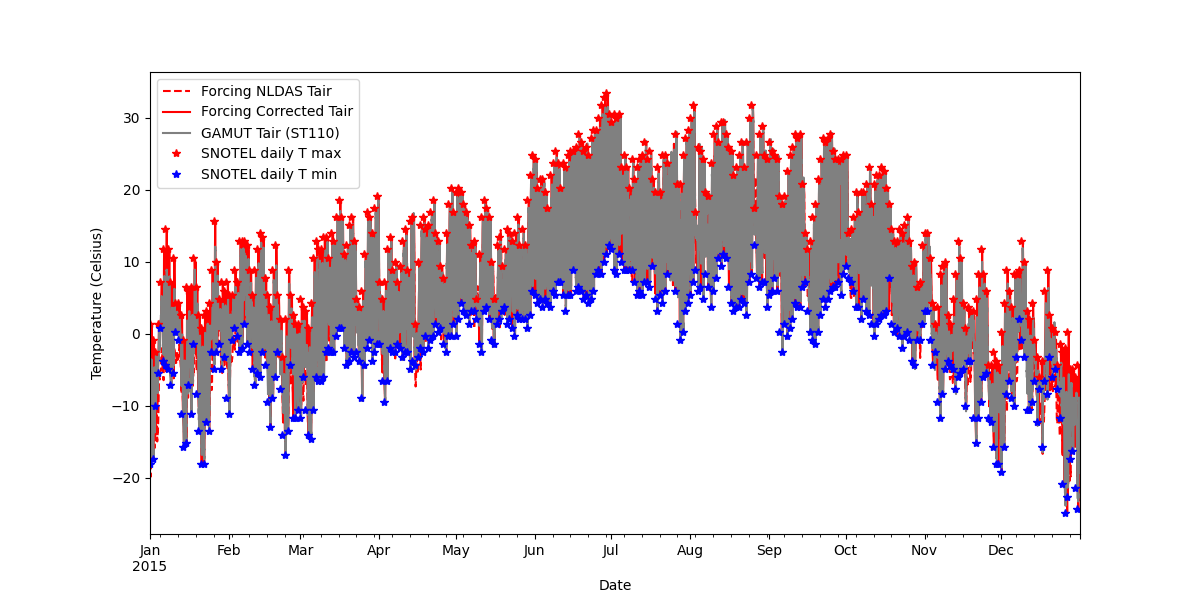

In [15]:
# Plot Tair and compare to ST110 data
fig, ax = plt.subplots(figsize=(12, 6))
Tair_raw_celsius[start_date:end_date].plot(ax=ax, label='Forcing NLDAS Tair', color='r', linestyle='--')
Tair_downscaled_celsius[start_date:end_date].plot(ax=ax, label='Forcing Corrected Tair', color='r', linestyle='-')
Tair_ST110[start_date:end_date].plot(ax=ax, label='GAMUT Tair (ST110)', color='grey', linestyle='-')
snotel.data.loc[start_date:end_date,'T_max_C'].plot(ax=ax, label='SNOTEL daily T max', color='r', marker='*', linestyle='None')
snotel.data.loc[start_date:end_date,'T_min_C'].plot(ax=ax, label='SNOTEL daily T min', color='b', marker='*', linestyle='None')
ax.legend()
ax.set_ylabel('Temperature (Celsius)')